# Occupations
How many occupations the database holds, how the five meta occupations split them, and which groups appear when occupations are linked by the people who hold them together.

In [1]:
import sys
import tempfile

import duckdb
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import polars as pl
sys.path.append('../notebooks_analysis')
from style import *

SEED = 42
np.random.seed(SEED)

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'

apply_style()

## Parameters

In [2]:
MIN_LINKS = 100
MIN_PAIR_COUNT = 20
MIN_COSINE = 0.02
LOUVAIN_RESOLUTION = 1.0
TOP_PER_META = 10
TOP_PER_CLUSTER = 12
META_ORDER = ['Culture', 'Discovery/Science', 'Leadership', 'Sports/Games', 'Other', 'missing']

## Load data
### Occupations per individual
One row per individual and distinct occupation qid. Labels and meta occupations come from the `occupation` table; qids absent from it are marked `missing`.

In [3]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")

con.sql("""
    CREATE TEMP TABLE individual_occupation AS
    SELECT DISTINCT entity.qid AS person, occupation_item.entity.qid AS occupation_qid
    FROM   individual, unnest(occupation) AS unnested(occupation_item)
""")

con.sql("""
    CREATE TEMP TABLE occupation_count AS
    SELECT   individual_occupation.occupation_qid,
             coalesce(occupation.entity.label_en, individual_occupation.occupation_qid) AS label,
             coalesce(occupation.meta_occupation, 'missing') AS meta_occupation,
             occupation.entity.qid IS NOT NULL AS in_occupation_table,
             count(*) AS individuals
    FROM     individual_occupation
    LEFT JOIN occupation ON occupation.entity.qid = individual_occupation.occupation_qid
    GROUP BY ALL
""")

occupations = con.sql('SELECT * FROM occupation_count ORDER BY individuals DESC').pl()
assert occupations['occupation_qid'].is_unique
print(f'{occupations.height:,} distinct occupations used')
occupations.head()

22,037 distinct occupations used


occupation_qid,label,meta_occupation,in_occupation_table,individuals
str,str,str,bool,i64
"""Q1650915""","""researcher""","""Discovery/Science""",true,2087136
"""Q82955""","""politician""","""Leadership""",true,912043
"""Q36180""","""writer""","""Culture""",true,399201
"""Q937857""","""association football player""","""Sports/Games""",true,384851
"""Q33999""","""actor""","""Culture""",true,364585


### Individuals

In [4]:
individuals = con.sql("""
    SELECT count(*) AS individuals,
           count(*) FILTER (WHERE len(occupation) > 0) AS with_occupation
    FROM   individual
""").pl()
individuals

individuals,with_occupation
i64,i64
13002897,9038108


## Overview
### Table 1: Occupation counts

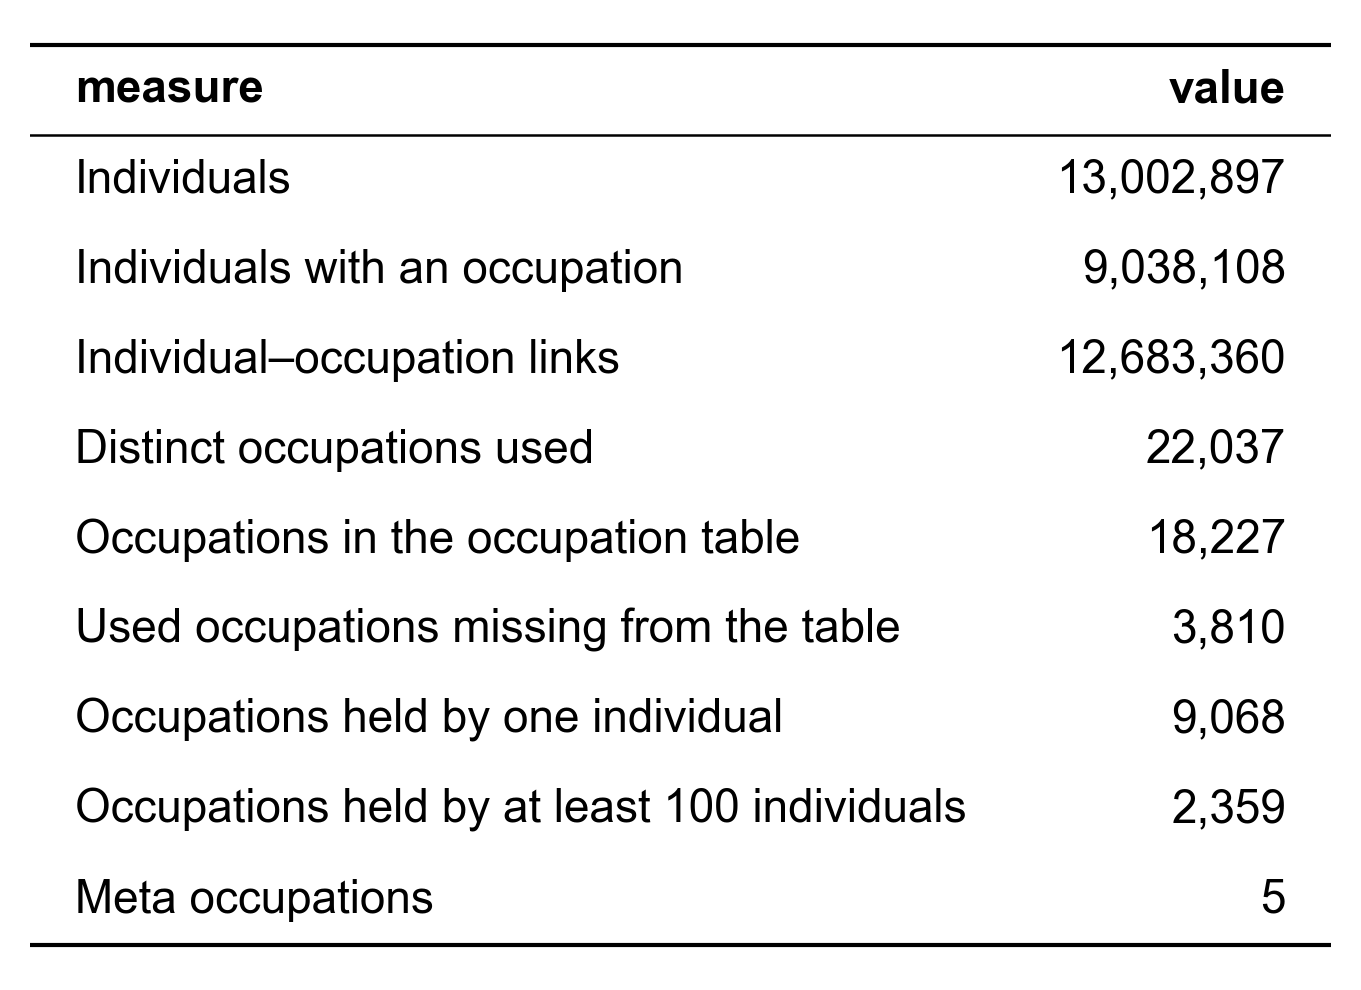

In [5]:
overview = pl.DataFrame({
    'measure': [
        'Individuals',
        'Individuals with an occupation',
        'Individual–occupation links',
        'Distinct occupations used',
        'Occupations in the occupation table',
        'Used occupations missing from the table',
        'Occupations held by one individual',
        f'Occupations held by at least {MIN_LINKS} individuals',
        'Meta occupations',
    ],
    'value': [
        individuals['individuals'][0],
        individuals['with_occupation'][0],
        int(occupations['individuals'].sum()),
        occupations.height,
        con.sql('SELECT count(*) FROM occupation').fetchone()[0],
        occupations.filter(~pl.col('in_occupation_table')).height,
        occupations.filter(pl.col('individuals') == 1).height,
        occupations.filter(pl.col('individuals') >= MIN_LINKS).height,
        occupations.filter(pl.col('meta_occupation') != 'missing')['meta_occupation'].n_unique(),
    ],
})
show_table(overview)

### Figure 1: Number of occupations per individual

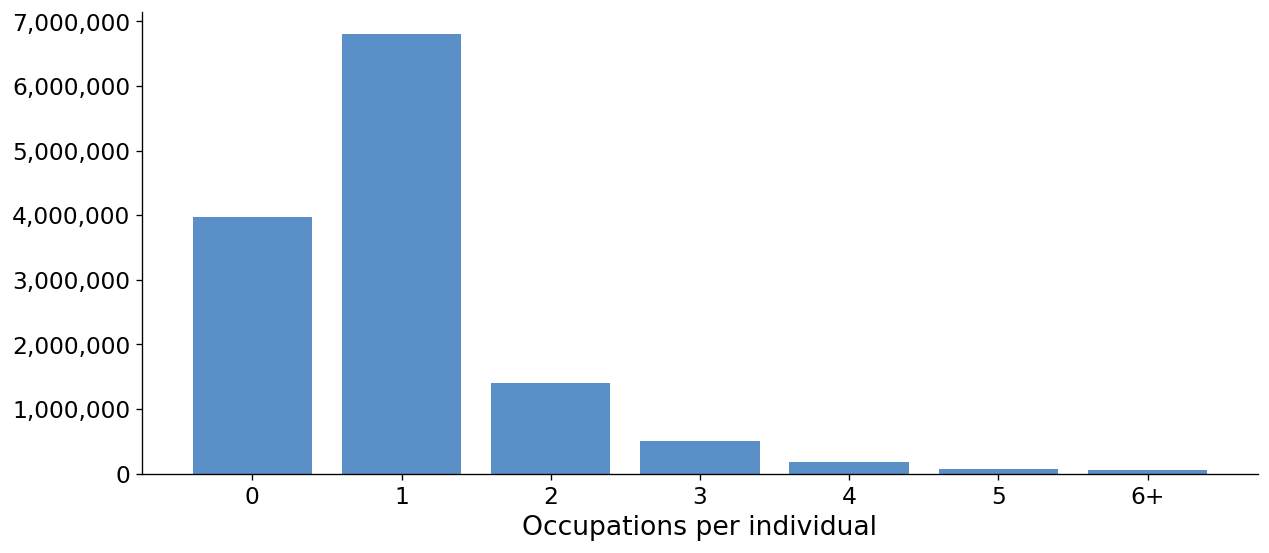

In [6]:
per_individual = con.sql("""
    SELECT least(len(occupation), 6) AS occupations, count(*) AS individuals
    FROM   individual
    GROUP BY 1 ORDER BY 1
""").pl()

fig, ax = plt.subplots()
ax.bar(per_individual['occupations'], per_individual['individuals'], color=MAIN_COLOR)
ax.set_xticks(per_individual['occupations'], [str(n) if n < 6 else '6+' for n in per_individual['occupations']])
ax.set_xlabel('Occupations per individual')
ax.yaxis.set_major_formatter(THOUSANDS)
plt.show()

### Figure 2: Long tail of occupations
Share of all individual–occupation links covered by the N most frequent occupations.

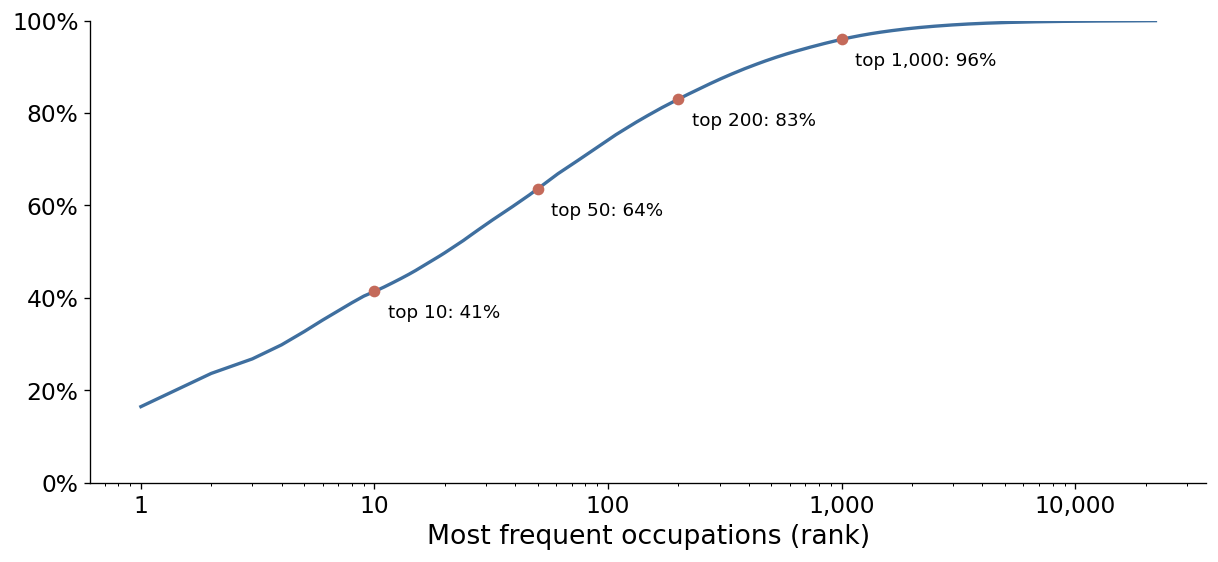

In [7]:
coverage = occupations.with_columns(
    rank=pl.int_range(1, pl.len() + 1),
    cumulative_share=pl.col('individuals').cum_sum() / pl.col('individuals').sum() * 100,
)

fig, ax = plt.subplots()
ax.plot(coverage['rank'], coverage['cumulative_share'], color=MAIN_LINE_COLOR)
for n in [10, 50, 200, 1000]:
    share = coverage['cumulative_share'][n - 1]
    ax.scatter(n, share, color=HIGHLIGHT_COLOR, zorder=3)
    ax.annotate(f'top {n:,}: {share:.0f}%', (n, share), xytext=(8, -16), textcoords='offset points', fontsize=POINT_LABEL_FONTSIZE)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(THOUSANDS)
ax.yaxis.set_major_formatter(PERCENT)
ax.set_xlabel('Most frequent occupations (rank)')
ax.set_ylim(0, 100)
plt.show()

## Meta occupations
Each occupation carries one of five Cross-Verified level-1 domains (enrichment step 09). Counted three ways: occupations, links, and individuals holding at least one occupation of the domain.

In [8]:
meta_individuals = con.sql("""
    SELECT   occupation_count.meta_occupation, count(DISTINCT individual_occupation.person) AS individuals
    FROM     individual_occupation
    JOIN     occupation_count USING (occupation_qid)
    GROUP BY 1
""").pl()

meta = (
    occupations.group_by('meta_occupation')
    .agg(occupations=pl.len(), links=pl.col('individuals').sum())
    .join(meta_individuals, on='meta_occupation')
    .with_columns(order=pl.col('meta_occupation').replace_strict({m: i for i, m in enumerate(META_ORDER)}))
    .sort('order').drop('order')
)
assert meta['occupations'].sum() == occupations.height
meta

meta_occupation,occupations,links,individuals
str,u32,i64,i64
"""Culture""",2974,3968291,2525029
"""Discovery/Science""",3854,4344174,3608671
"""Leadership""",5577,2363491,1941813
"""Sports/Games""",1126,1591540,1454092
"""Other""",4696,386039,357628
"""missing""",3810,29825,29182


### Figure 3: Occupations and individuals per meta occupation

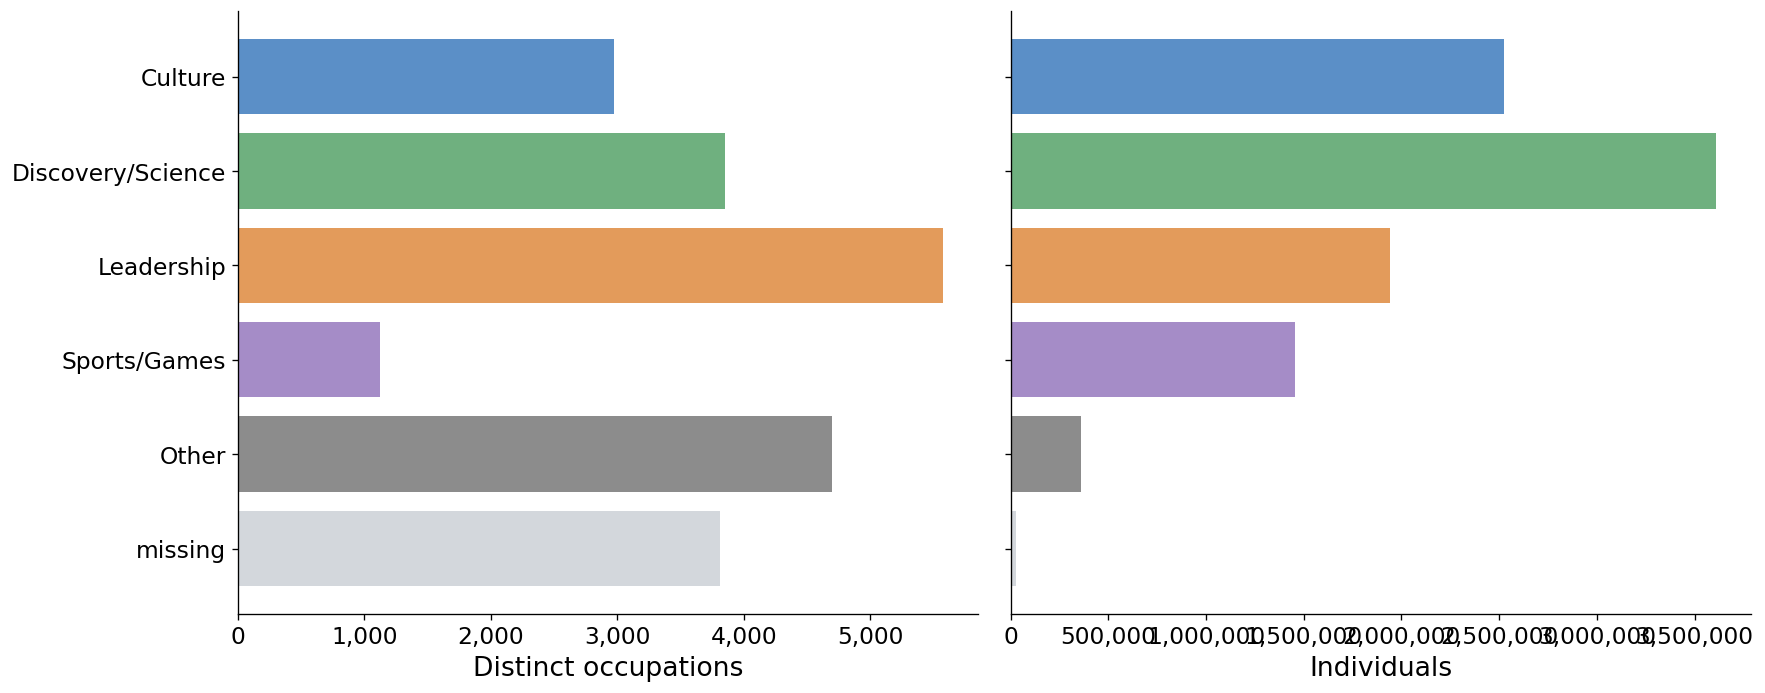

In [9]:
meta_colors = {**OCCUPATION_COLORS, 'Other': GREY, 'missing': LIGHT_GREY}
colors = [meta_colors[m] for m in meta['meta_occupation']]

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_WIDE)
for ax, column, label in [(axes[0], 'occupations', 'Distinct occupations'), (axes[1], 'individuals', 'Individuals')]:
    ax.barh(meta['meta_occupation'], meta[column], color=colors)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(THOUSANDS)
    ax.set_xlabel(label)
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

### Top occupations per meta occupation

In [10]:
top_per_meta = (
    occupations.sort('individuals', descending=True)
    .group_by('meta_occupation', maintain_order=True).head(TOP_PER_META)
    .select('meta_occupation', 'label', 'individuals')
)
with pl.Config(tbl_rows=-1, fmt_str_lengths=50):
    display(top_per_meta)

meta_occupation,label,individuals
str,str,i64
"""Discovery/Science""","""researcher""",2087136
"""Discovery/Science""","""university teacher""",316030
"""Discovery/Science""","""historian""",120663
"""Discovery/Science""","""physician""",109577
"""Discovery/Science""","""teacher""",92046
"""Discovery/Science""","""botanist""",64397
"""Discovery/Science""","""economist""",56651
"""Discovery/Science""","""engineer""",54986
"""Discovery/Science""","""mathematician""",46745


### Known issues
- One label can dominate a whole domain (share of the domain's links held by its largest occupation).
- Individuals whose occupations span several meta occupations are counted in each of them.

In [11]:
largest = (
    occupations.group_by('meta_occupation')
    .agg(largest=pl.col('label').sort_by('individuals').last(),
         share_of_links=(pl.col('individuals').max() / pl.col('individuals').sum() * 100).round(1))
    .sort('share_of_links', descending=True)
)
display(largest)

spread = con.sql("""
    SELECT   metas, count(*) AS individuals
    FROM     (SELECT individual_occupation.person, count(DISTINCT occupation_count.meta_occupation) AS metas
              FROM individual_occupation JOIN occupation_count USING (occupation_qid)
              WHERE occupation_count.meta_occupation NOT IN ('Other', 'missing')
              GROUP BY 1)
    GROUP BY 1 ORDER BY 1
""").pl().with_columns(share=(pl.col('individuals') / pl.col('individuals').sum() * 100).round(1))
spread

meta_occupation,largest,share_of_links
str,str,f64
"""Discovery/Science""","""researcher""",48.0
"""Leadership""","""politician""",38.6
"""Sports/Games""","""association football player""",24.2
"""Other""","""translator""",19.7
"""Culture""","""writer""",10.1
"""missing""","""Q97768146""",9.0


metas,individuals,share
i64,i64,f64
1,8303452,93.4
2,547443,6.2
3,43065,0.5
4,518,0.0


## Co-occupation network
Two occupations are linked when the same individuals hold both. Only occupations held by at least `MIN_LINKS` individuals enter. Raw counts favour big occupations (researcher, politician), so edges are weighted by cosine similarity, `pairs / sqrt(n_a × n_b)`, and kept when `pairs ≥ MIN_PAIR_COUNT` and `cosine ≥ MIN_COSINE`. Louvain communities then give the groups the data suggests.

### Pairs

In [12]:
con.sql("""
    CREATE TEMP TABLE frequent_link AS
    SELECT individual_occupation.*
    FROM   individual_occupation
    JOIN   occupation_count USING (occupation_qid)
    WHERE  occupation_count.individuals >= $min_links
""", params={'min_links': MIN_LINKS})

pairs = con.sql("""
    SELECT   first_link.occupation_qid AS source, second_link.occupation_qid AS target, count(*) AS pairs
    FROM     frequent_link AS first_link
    JOIN     frequent_link AS second_link
             ON first_link.person = second_link.person AND first_link.occupation_qid < second_link.occupation_qid
    GROUP BY 1, 2
""").pl()
print(f'{pairs.height:,} occupation pairs')

counts = occupations.select('occupation_qid', 'individuals')
edges = (
    pairs.join(counts.rename({'occupation_qid': 'source', 'individuals': 'n_source'}), on='source')
    .join(counts.rename({'occupation_qid': 'target', 'individuals': 'n_target'}), on='target')
    .with_columns(cosine=pl.col('pairs') / (pl.col('n_source') * pl.col('n_target')).sqrt())
)
edges = edges.filter((pl.col('pairs') >= MIN_PAIR_COUNT) & (pl.col('cosine') >= MIN_COSINE)).sort('source', 'target')
print(f'{edges.height:,} edges kept')

labels = dict(zip(occupations['occupation_qid'], occupations['label']))
edges.sort('cosine', descending=True).head(10).with_columns(
    pl.col('source').replace_strict(labels), pl.col('target').replace_strict(labels))

228,997 occupation pairs
4,032 edges kept


source,target,pairs,n_source,n_target,cosine
str,str,i64,i64,i64,f64
"""Marineoffizier""","""submariner""",1317,1506,1751,0.811017
"""Catholic priest""","""Catholic bishop""",41479,80607,44121,0.695535
"""harness racehorse trainer""","""harness racer""",136,150,276,0.668404
"""black-figure vase painter""","""Attic vase-painter""",132,170,325,0.561575
"""red-figure vase painter""","""Attic vase-painter""",149,241,325,0.532398
"""man of letters""","""literary scholar""",3838,4071,15203,0.487854
"""botanical collector""","""scientific collector""",4064,11525,6113,0.484179
"""television actor""","""film actor""",29680,51116,82378,0.457383
"""farm operator""","""Q97768146""",1619,4963,2681,0.44384


### Communities

In [13]:
graph = nx.Graph()
graph.add_weighted_edges_from(edges.select('source', 'target', 'cosine').rows())
frequent = occupations.filter(pl.col('individuals') >= MIN_LINKS)
print(f'{frequent.height:,} frequent occupations, {graph.number_of_nodes():,} in the network, '
      f'{frequent.height - graph.number_of_nodes():,} isolated')

communities = nx.community.louvain_communities(graph, weight='weight', resolution=LOUVAIN_RESOLUTION, seed=SEED)
membership = pl.DataFrame(
    [(qid, i) for i, members in enumerate(communities) for qid in members],
    schema=['occupation_qid', 'cluster'], orient='row',
)
clustered = membership.join(occupations, on='occupation_qid')
assert clustered.height == graph.number_of_nodes()
print(f'{len(communities)} communities, modularity {nx.community.modularity(graph, communities, weight="weight"):.2f}')

2,359 frequent occupations, 1,488 in the network, 871 isolated
80 communities, modularity 0.84


### Table 2: Communities and their top occupations
Sorted by number of individual–occupation links. `main_meta` is the meta occupation holding most of the community's links, `meta_purity` its share.

In [14]:
meta_by_cluster = (
    clustered.group_by('cluster', 'meta_occupation').agg(links=pl.col('individuals').sum())
    .sort('links', descending=True)
    .group_by('cluster', maintain_order=True)
    .agg(main_meta=pl.col('meta_occupation').first(),
         meta_purity=(pl.col('links').first() / pl.col('links').sum() * 100).round(0))
)
cluster_summary = (
    clustered.sort('individuals', descending=True)
    .group_by('cluster', maintain_order=True)
    .agg(occupations=pl.len(), links=pl.col('individuals').sum(),
         top_occupations=pl.col('label').head(TOP_PER_CLUSTER).str.join(', '))
    .join(meta_by_cluster, on='cluster')
    .sort('links', descending=True)
    .with_columns(cluster=pl.int_range(1, pl.len() + 1))
    .select('cluster', 'occupations', 'links', 'main_meta', 'meta_purity', 'top_occupations')
)
with pl.Config(tbl_rows=-1, fmt_str_lengths=400, tbl_width_chars=600):
    display(cluster_summary)

cluster,occupations,links,main_meta,meta_purity,top_occupations
i64,u32,i64,str,f64,str
1,187,4424898,"""Discovery/Science""",74.0,"""researcher, writer, university teacher, journalist, poet, historian, teacher, translator, author, economist, mathematician, scientist"""
2,115,1445452,"""Leadership""",93.0,"""politician, lawyer, jurist, diplomat, judge, civil servant, farmer, pensioner, minister, trade unionist, business executive, statesperson"""
3,90,1049104,"""Culture""",100.0,"""actor, film director, film actor, screenwriter, television actor, film producer, stage actor, director, television presenter, cinematographer, voice actor, film editor"""
4,57,946519,"""Sports/Games""",100.0,"""association football player, basketball player, athletics competitor, American football player, association football coach, baseball player, athlete, coach, basketball coach, association football referee, sprinter, sport shooter"""
5,117,775286,"""Culture""",99.0,"""painter, artist, photographer, visual artist, sculptor, illustrator, draftsperson, graphic artist, designer, printmaker, comics artist, ceramicist"""
6,102,681190,"""Culture""",95.0,"""singer, composer, musician, songwriter, pianist, conductor, opera singer, singer-songwriter, record producer, guitarist, music educator, musicologist"""
7,115,353037,"""Discovery/Science""",88.0,"""botanist, entomologist, biologist, zoologist, geologist, geographer, botanical collector, naval officer, announcer, pharmacist, biochemist, paleontologist"""
8,83,349767,"""Leadership""",79.0,"""Catholic priest, Catholic bishop, theologian, pastor, priest, missionary, Christian minister, rabbi, cleric, monk, curate, presbyter"""
9,46,325892,"""Leadership""",61.0,"""military personnel, engineer, military officer, soldier, military leader, civil engineer, aircraft pilot, inventor, nurse, racing automobile driver, racing driver, motorcycle racer"""


### Figure 4: Meta occupations inside each community
Share of each community's links per meta occupation, for the 25 largest communities. Mixed bars show where the five domains cut across natural groups.

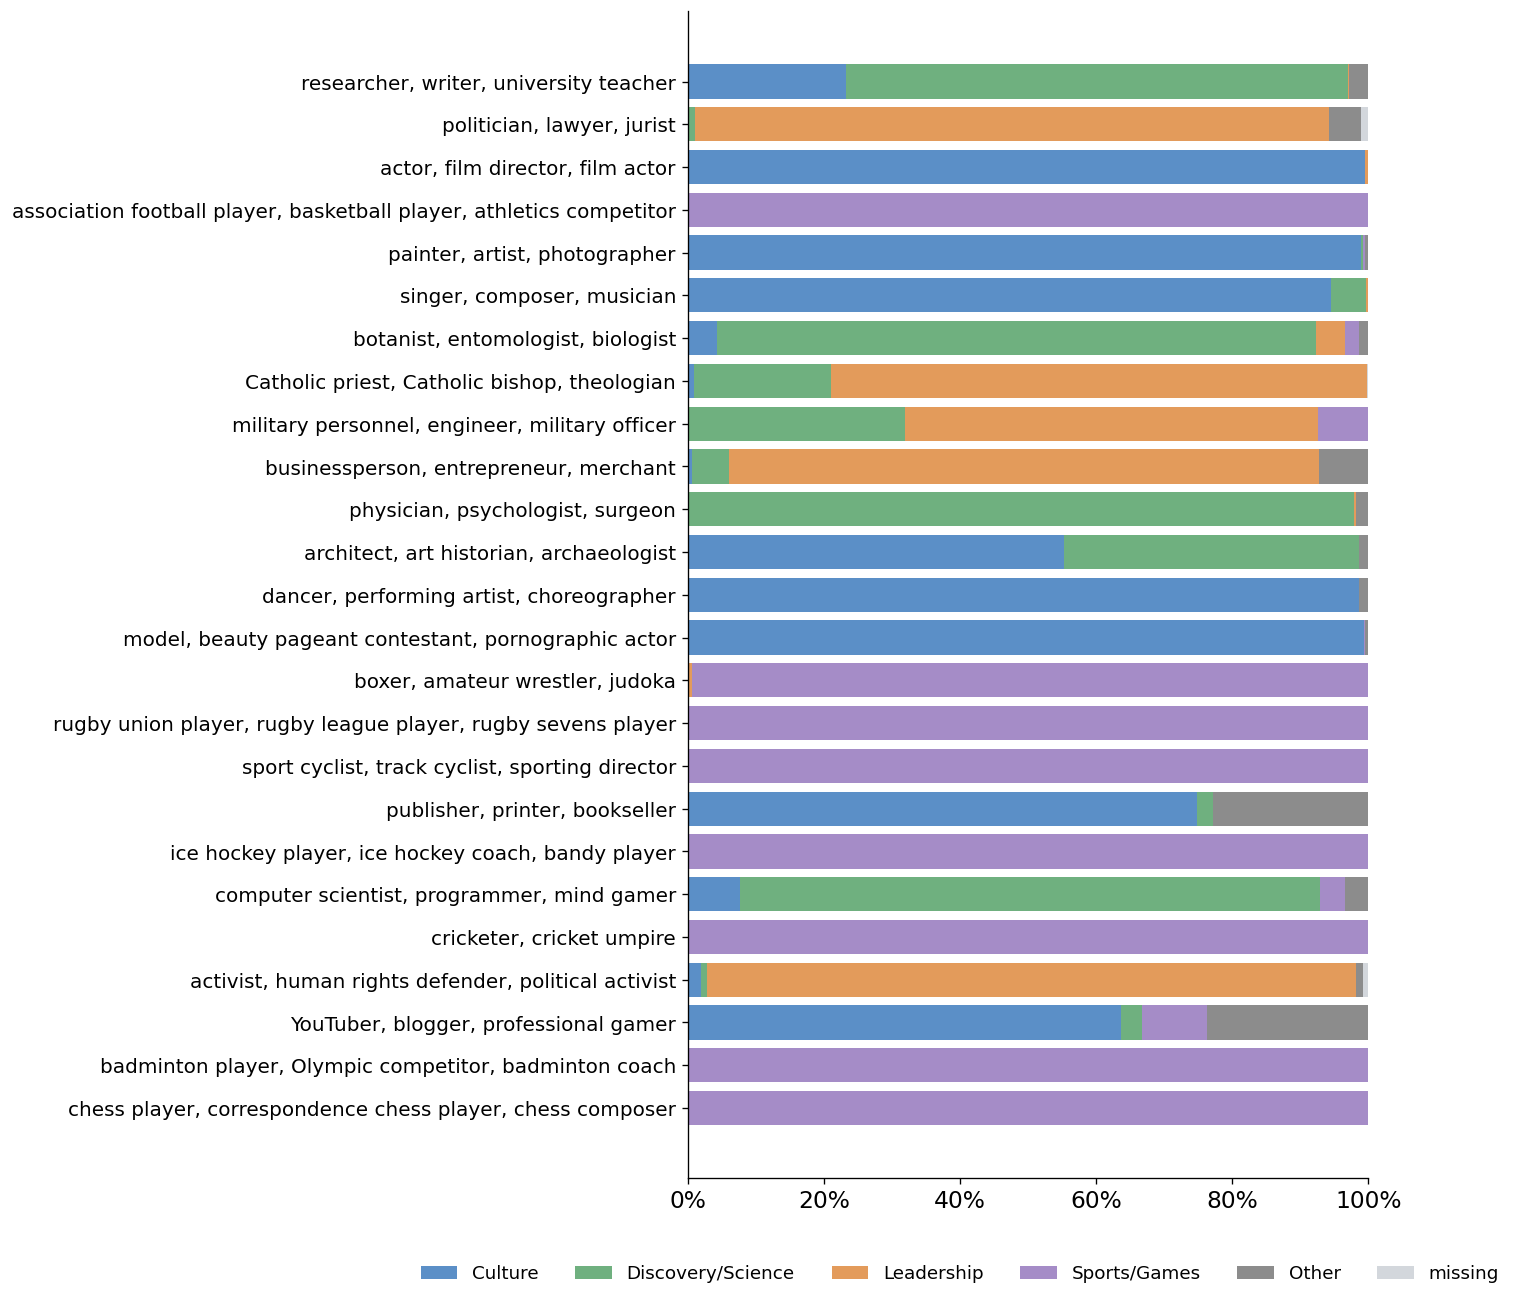

In [15]:
top_clusters = cluster_summary.head(25)
cluster_rank = dict(zip(
    clustered.group_by('cluster').agg(links=pl.col('individuals').sum()).sort('links', descending=True)['cluster'],
    range(1, clustered['cluster'].n_unique() + 1),
))
mix = (
    clustered.with_columns(rank=pl.col('cluster').replace_strict(cluster_rank))
    .filter(pl.col('rank') <= top_clusters.height)
    .group_by('rank', 'meta_occupation').agg(links=pl.col('individuals').sum())
    .with_columns(share=pl.col('links') / pl.col('links').sum().over('rank') * 100)
    .pivot(on='meta_occupation', index='rank', values='share').fill_null(0).sort('rank')
)
first_labels = [', '.join(t.split(', ')[:3]) for t in top_clusters['top_occupations']]

fig, ax = plt.subplots(figsize=(12, 11))
left = np.zeros(mix.height)
for m in [m for m in META_ORDER if m in mix.columns]:
    ax.barh(first_labels, mix[m], left=left, color=meta_colors[m], label=m)
    left += mix[m].to_numpy()
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PERCENT)
ax.set_xlim(0, 100)
ax.tick_params(axis='y', labelsize=LONG_TICK_LABEL_FONTSIZE)
ax.legend(loc='upper center', bbox_to_anchor=(0.4, -0.06), ncol=6, fontsize=SMALL_LEGEND_FONTSIZE)
plt.tight_layout()
plt.show()

### Close the connection

In [16]:
con.close()